# Plate Detector Evaluation

Evaluates every trained detector on the same test sets and compares them with the results reported by Hasin et al. (2026).

| Test set | Images | Metrics |
|---|---|---|
| Paper test (Hossain localization test split) | 553 | Paper metrics: accuracy, precision, recall, F1, IoU; plus mAP |
| Full test (all sources) | 865 | mAP@0.5, mAP@0.5:0.95, precision, recall |

**Paper metrics, as defined here**
- **Accuracy:** an image with plates is correct if every plate is detected with IoU > 0.7; an image without plates is correct if nothing is detected.
- **Precision / recall / F1:** detections matched one-to-one to plates at IoU ≥ 0.5.
- **IoU:** mean IoU of each plate with its best-matching detection.

Predictions use confidence 0.25.

**Setup (Kaggle notebook)**
1. Add `bangla-plate-detection` and `lpr-traning-output-test` as inputs. Each model folder in it holds `weights/best.pt`; the folder name is used as the model name.
2. Accelerator: **GPU**.

In [1]:
%pip install -q ultralytics==8.4.46

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 24.8 MB/s eta 0:00:0000:01
Note: you may need to restart the kernel to use updated packages.


## Setup

In [2]:
import json
import shutil
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from ultralytics import YOLO

WORK = Path("/kaggle/working")
INPUT = Path("/kaggle/input")
IMGSZ = 640
CONF = 0.25
DEVICE = 0 if torch.cuda.is_available() else "cpu"

DATA = WORK / "plate-detection"
if not DATA.exists():
    shutil.copytree(next(p for p in INPUT.rglob("bangla-plate-detection") if p.is_dir()), DATA)

WEIGHTS = next(p for p in INPUT.rglob("lpr-traning-output-test") if p.is_dir())
MODELS = {best.parent.parent.name: best for best in sorted(WEIGHTS.rglob("weights/best.pt"))}
print("Models:", list(MODELS))

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
Models: ['yolo26n', 'yolo26s', 'yolov26m', 'yolov8m-paper', 'yolov8m-paper-2stage-stage1', 'yolov8m-paper-2stage-stage2']


## Test sets

In [3]:
def make_test_set(name: str, prefix: str = "") -> Path:
    root = WORK / "eval" / name
    for kind in ("images", "labels"):
        folder = root / kind / "test"
        folder.mkdir(parents=True, exist_ok=True)
        for f in (DATA / kind / "test").glob(f"{prefix}*"):
            link = folder / f.name
            if not link.exists():
                link.symlink_to(f)
    yaml_path = root / "data.yaml"
    yaml_path.write_text(f"path: {root}\ntrain: images/test\nval: images/test\ntest: images/test\n"
                         "names:\n  0: license_plate\n")
    return yaml_path


TEST_SETS = {"paper": make_test_set("paper", "bd-lpr__"), "full": make_test_set("full")}
for name, yaml_path in TEST_SETS.items():
    print(f"{name:6} {len(list((yaml_path.parent / 'images' / 'test').iterdir()))} images")

paper  553 images
full   865 images


## Paper metrics

In [4]:
def iou_matrix(a: np.ndarray, b: np.ndarray) -> np.ndarray:
    x1 = np.maximum(a[:, None, 0], b[None, :, 0])
    y1 = np.maximum(a[:, None, 1], b[None, :, 1])
    x2 = np.minimum(a[:, None, 2], b[None, :, 2])
    y2 = np.minimum(a[:, None, 3], b[None, :, 3])
    inter = np.clip(x2 - x1, 0, None) * np.clip(y2 - y1, 0, None)
    area = lambda r: (r[:, 2] - r[:, 0]) * (r[:, 3] - r[:, 1])
    return inter / (area(a)[:, None] + area(b)[None, :] - inter + 1e-9)


def greedy_match(iou: np.ndarray, threshold: float) -> int:
    used_gt, used_pred, matches = set(), set(), 0
    for g, p in zip(*np.unravel_index(np.argsort(-iou, axis=None), iou.shape)):
        if iou[g, p] < threshold:
            break
        if g not in used_gt and p not in used_pred:
            used_gt.add(g)
            used_pred.add(p)
            matches += 1
    return matches


def ground_truth(label_path: Path, width: int, height: int) -> np.ndarray:
    rows = [list(map(float, l.split()[1:])) for l in label_path.read_text().splitlines() if l.strip()]
    if not rows:
        return np.zeros((0, 4))
    xc, yc, w, h = np.array(rows).T
    return np.stack([(xc - w / 2) * width, (yc - h / 2) * height, (xc + w / 2) * width, (yc + h / 2) * height], 1)


def paper_metrics(model: YOLO, image_dir: Path) -> dict:
    correct, tp, fp, fn, ious = 0, 0, 0, 0, []
    images = sorted(image_dir.iterdir())
    label_dir = image_dir.parent.parent / "labels" / "test"
    BATCH = 16
    results = (r for i in range(0, len(images), BATCH)
               for r in model.predict([str(p) for p in images[i:i + BATCH]], imgsz=IMGSZ, conf=CONF,
                                      device=DEVICE, verbose=False))
    for path, result in zip(images, results):
        height, width = result.orig_shape
        gt = ground_truth(label_dir / f"{path.stem}.txt", width, height)

        pred = result.boxes.xyxy.cpu().numpy()

        if len(gt) == 0:
            correct += int(len(pred) == 0)
            fp += len(pred)
            continue

        iou = iou_matrix(gt, pred) if len(pred) else np.zeros((len(gt), 0))
        best = iou.max(axis=1) if len(pred) else np.zeros(len(gt))
        ious.extend(best.tolist())
        correct += int((best > 0.7).all())

        matches = greedy_match(iou, threshold=0.5)
        tp += matches
        fn += len(gt) - matches
        fp += len(pred) - matches

    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    return {
        "Accuracy": 100 * correct / len(images),
        "Precision": 100 * precision,
        "Recall": 100 * recall,
        "F1": 100 * 2 * precision * recall / (precision + recall) if precision + recall else 0.0,
        "IoU": 100 * float(np.mean(ious)) if ious else 0.0,
    }


def map_metrics(model: YOLO, yaml_path: Path, name: str) -> dict:
    m = model.val(data=str(yaml_path), split="test", imgsz=IMGSZ, device=DEVICE, plots=False,
                  project=str(WORK / "val"), name=name, exist_ok=True, verbose=False)
    return {"mAP50": 100 * float(m.box.map50), "mAP50-95": 100 * float(m.box.map),
            "inference_ms": float(m.speed["inference"])}

In [5]:
import gc
gc.collect()
torch.cuda.empty_cache()


## Evaluate

In [6]:
rows = []
for name, weights in sorted(MODELS.items()):
    model = YOLO(weights)
    paper = paper_metrics(model, TEST_SETS["paper"].parent / "images" / "test")
    paper_map = map_metrics(model, TEST_SETS["paper"], f"{name}-paper")
    full_map = map_metrics(model, TEST_SETS["full"], f"{name}-full")
    rows.append({"Model": name, "Source": "ours", **paper,
                 "mAP50 (paper test)": paper_map["mAP50"], "mAP50-95 (paper test)": paper_map["mAP50-95"],
                 "mAP50 (full test)": full_map["mAP50"], "mAP50-95 (full test)": full_map["mAP50-95"],
                 "Inference (ms)": full_map["inference_ms"]})
    del model
    torch.cuda.empty_cache()

ours = pd.DataFrame(rows)

Ultralytics 8.4.46 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3179.9±1113.7 MB/s, size: 243.1 KB)
val: Scanning /kaggle/working/eval/paper/labels/test... 553 images, 162 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 553/553 1.5Kit/s 0.4s0.1ss
val: New cache created: /kaggle/working/eval/paper/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 35/35 7.4it/s 4.7s<0.2s
                   all        553        398      0.976       0.96      0.991      0.728
Speed: 0.7ms preprocess, 3.6ms inference, 0.0ms loss, 0.1ms postprocess per image
Ultralytics 8.4.46 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1566.0±787.7 MB/s, size: 62.4 KB)
val: Scanning /kaggle/working/eval/full/labels/test... 865 images, 162 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 865/865 1.4Kit/s 0.6s0.1ss
val: New ca

## Comparison with the paper

In [7]:
PAPER = pd.DataFrame([
    ("U-Net", 91.43, 93.19, 89.71, 91.41, 82.1),
    ("YOLOv5m", 90.97, 99.89, 87.03, 93.06, 83.9),
    ("YOLOv7m", 67.15, 95.28, 54.59, 69.42, 63.5),
    ("YOLOv8m", 97.11, 99.93, 95.68, 97.79, 89.7),
    ("YOLOv8m + multi-stage", 97.83, 99.44, 96.31, 98.37, 91.3),
    ("YOLOv9m", 95.67, 99.44, 95.20, 97.24, 88.8),
    ("YOLOv11m", 96.39, 99.87, 95.14, 97.51, 89.2),
], columns=["Model", "Accuracy", "Precision", "Recall", "F1", "IoU"]).assign(Source="paper")

table = pd.concat([PAPER, ours], ignore_index=True)
table = table[["Model", "Source", "Accuracy", "Precision", "Recall", "F1", "IoU",
               "mAP50 (paper test)", "mAP50-95 (paper test)", "mAP50 (full test)", "mAP50-95 (full test)",
               "Inference (ms)"]]
table.to_csv(WORK / "plate_detector_comparison.csv", index=False)
table.round(2)

,Model,Source,Accuracy,Precision,Recall,F1,IoU,mAP50 (paper test),mAP50-95 (paper test),mAP50 (full test),mAP50-95 (full test),Inference (ms)
0,U-Net,paper,91.43,93.19,89.71,91.41,82.10,NaN,NaN,NaN,NaN,NaN
1,YOLOv5m,paper,90.97,99.89,87.03,93.06,83.90,NaN,NaN,NaN,NaN,NaN
2,YOLOv7m,paper,67.15,95.28,54.59,69.42,63.50,NaN,NaN,NaN,NaN,NaN
3,YOLOv8m,paper,97.11,99.93,95.68,97.79,89.70,NaN,NaN,NaN,NaN,NaN
4,YOLOv8m + multi-stage,paper,97.83,99.44,96.31,98.37,91.30,NaN,NaN,NaN,NaN,NaN
5,YOLOv9m,paper,95.67,99.44,95.20,97.24,88.80,NaN,NaN,NaN,NaN,NaN
6,YOLOv11m,paper,96.39,99.87,95.14,97.51,89.20,NaN,NaN,NaN,NaN,NaN
7,yolo26n,ours,96.20,93.56,98.49,95.96,85.01,99.15,72.84,98.05,72.99,3.01
8,yolo26s,ours,96.20,95.33,97.49,96.40,84.78,98.97,74.28,97.99,73.73,7.66
9,yolov26m,ours,96.02,90.14,98.74,94.24,85.95,98.75,74.35,97.82,73.91,23.66


## Sample predictions

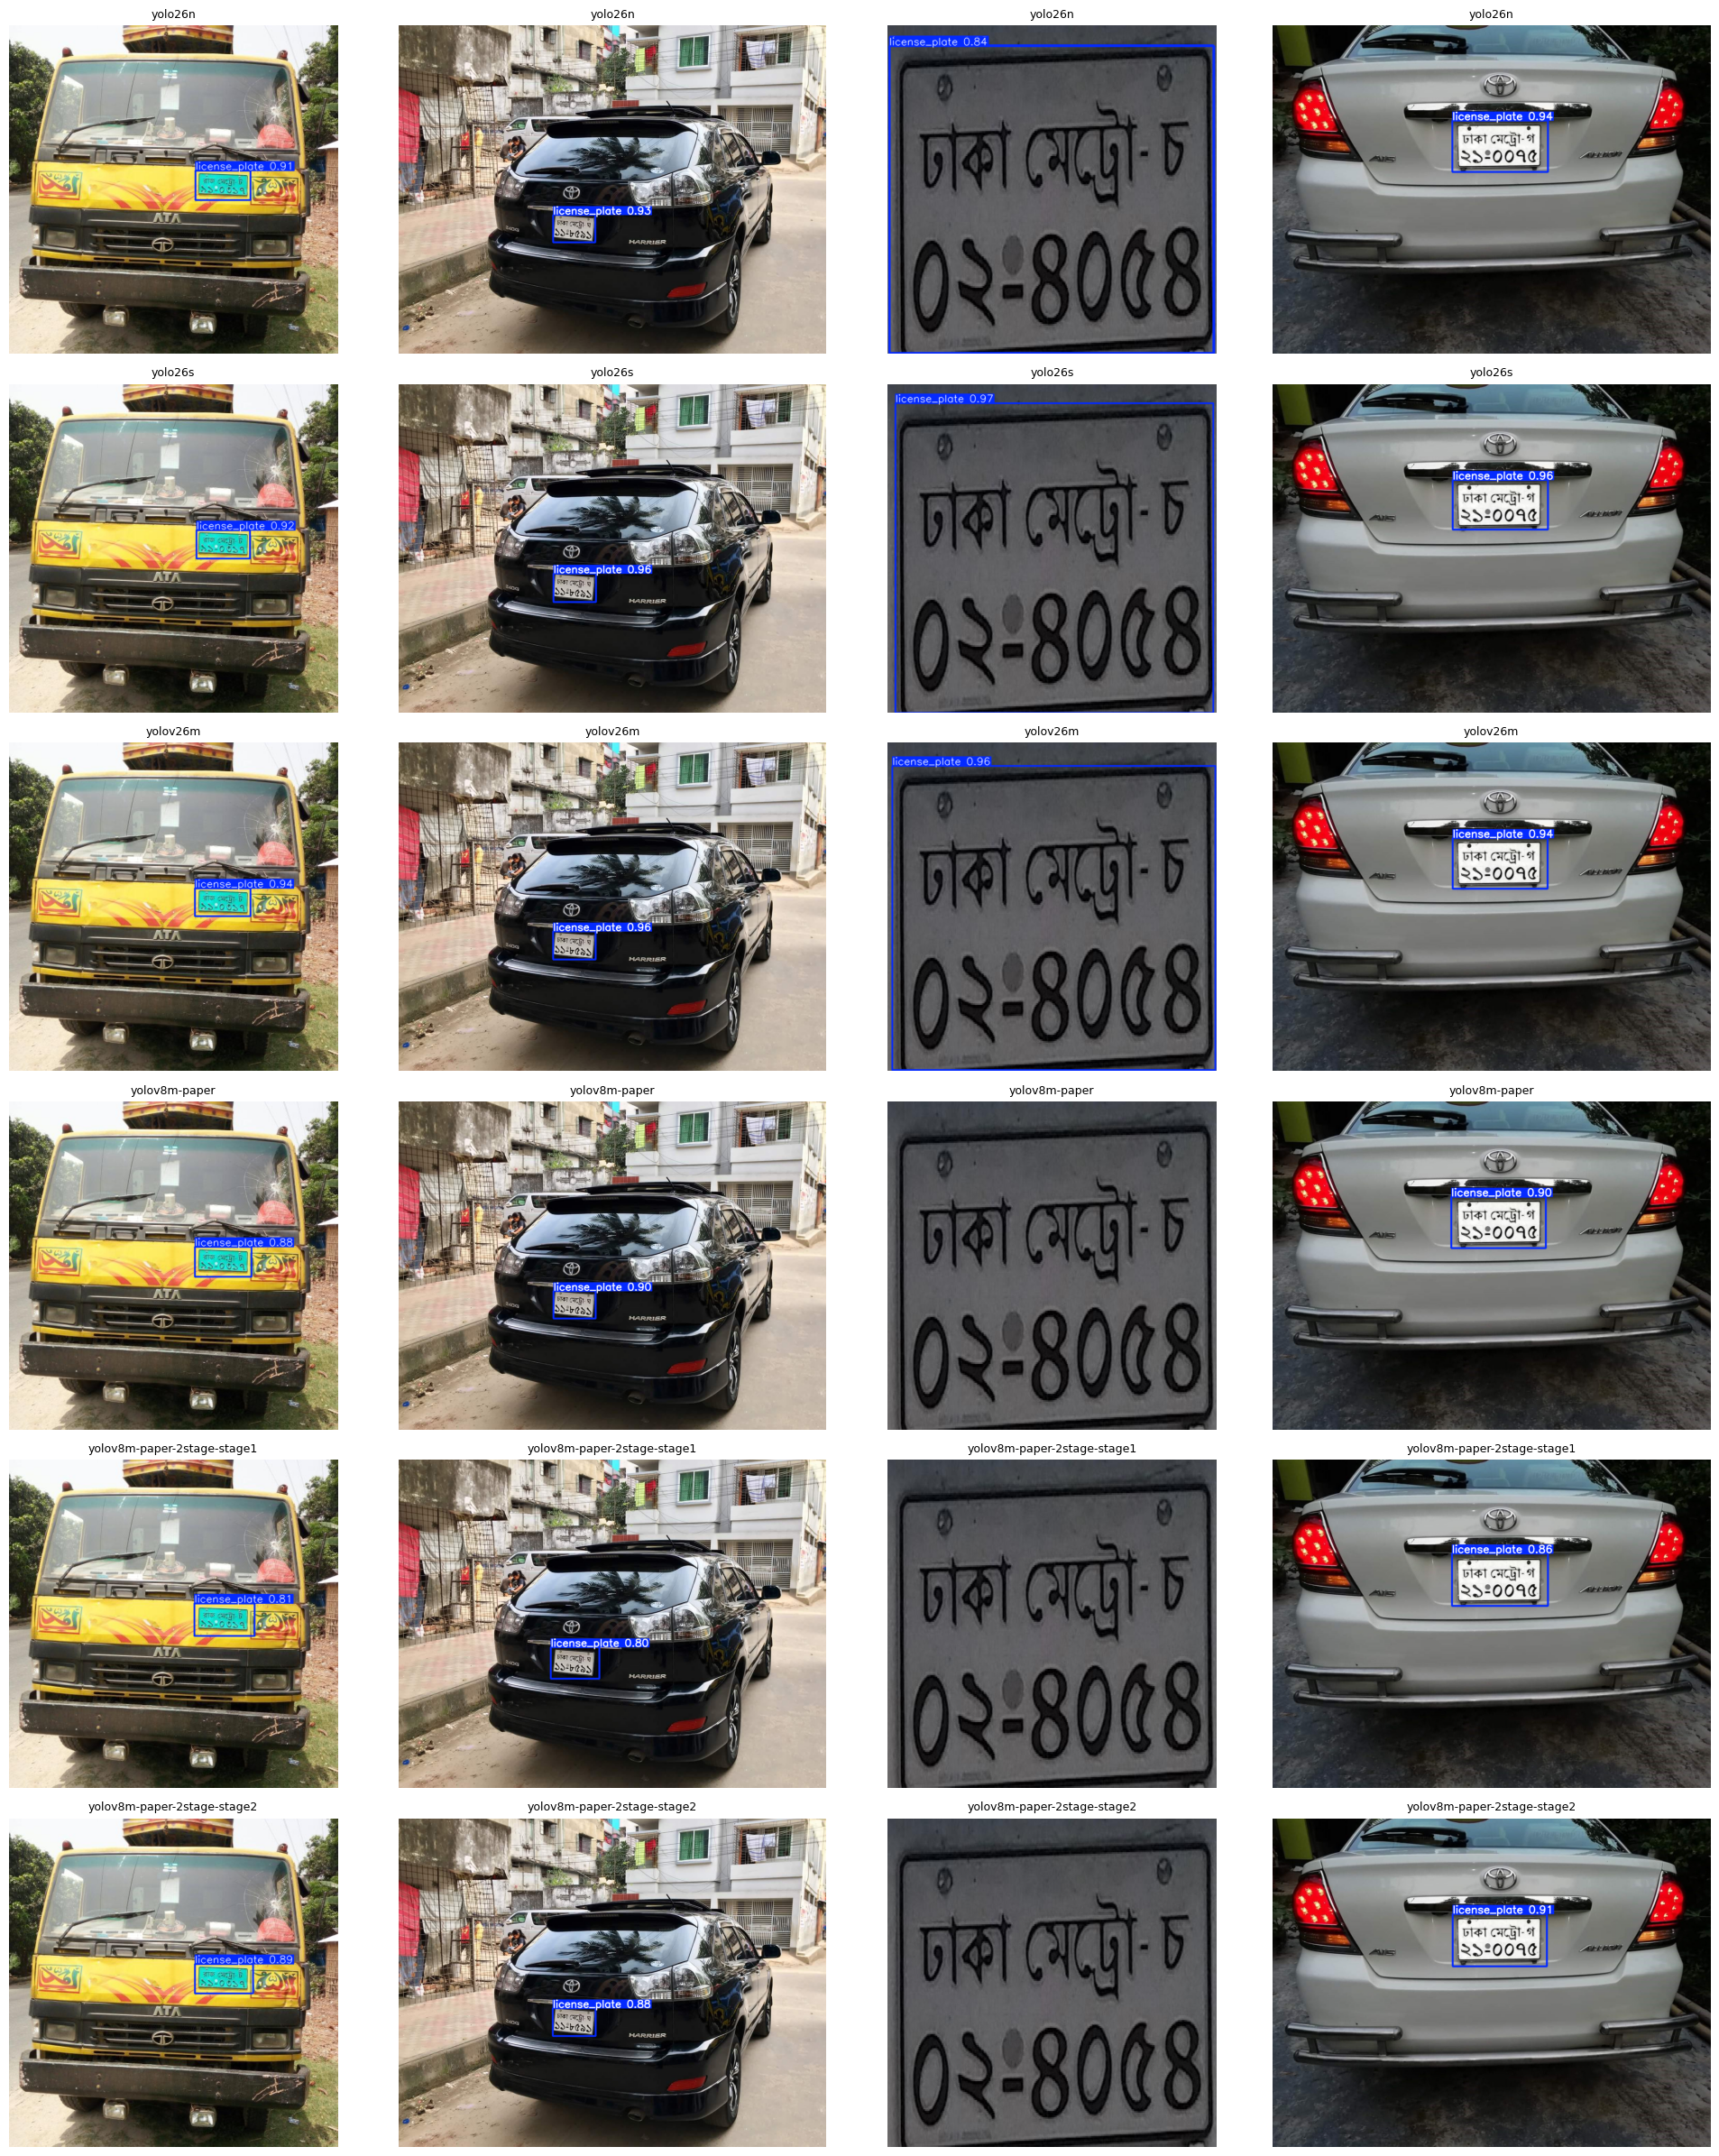

In [8]:
import random
import matplotlib.pyplot as plt

random.seed(0)
samples = random.sample(sorted((TEST_SETS["full"].parent / "images" / "test").iterdir()), 4)
fig, axes = plt.subplots(len(MODELS), len(samples), figsize=(5 * len(samples), 4 * len(MODELS)), squeeze=False)
for row, (name, weights) in zip(axes, sorted(MODELS.items())):
    for ax, result in zip(row, YOLO(weights).predict([str(p) for p in samples], imgsz=IMGSZ, conf=CONF,
                                                     device=DEVICE, verbose=False)):
        ax.imshow(result.plot()[:, :, ::-1])
        ax.set_title(name, fontsize=9)
        ax.axis("off")
plt.tight_layout()
plt.show()